# Banda simple con la banda siempre encendida: supervisor del emisor para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_banda_simple_emisor_openplc.ipynb)

La escena es `banda_simple.factoryio`, en la carpeta `Factory scenes`: un **emisor** deja cajas al
comienzo de una banda de rodillos; la banda las lleva hasta una rampa que termina en un removedor.
Dos sensores retrorreflectivos vigilan la banda: `SensorInicio`, bajo el emisor, y `SensorFin`,
antes de la rampa.

En este modelo la **banda está siempre encendida** y el supervisor solo controla el emisor. El
emisor funciona al inicio y se apaga cuando la caja que sacó corta el haz de `SensorInicio`.
Vuelve a emitir **solo cuando la caja sale** de `SensorFin`, y se apaga otra vez con la caja
siguiente. Así hay una sola caja en la banda a la vez.

El notebook
[`LCS_banda_simple_openplc`](LCS_banda_simple_openplc.ipynb) resuelve la misma escena con un
supervisor que además apaga y enciende la banda.

In [3]:
#@title Instalación de DESlab desde GitHub (solo en Colab; ejecute esta celda primero)
import importlib, shutil, subprocess, sys

if "google.colab" in sys.modules:
    if shutil.which("dot") is None:
        subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)
    %pip install -q networkx graphviz
    %pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git
    importlib.invalidate_caches()
    for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
        del sys.modules[name]
else:
    print("Fuera de Colab se usa el DESlab instalado en el entorno")

Fuera de Colab se usa el DESlab instalado en el entorno


In [1]:
from deslab import *

## 1. Señales de la escena y eventos

Los sensores son retrorreflectivos: valen 1 cuando el haz llega al reflector, es decir, cuando
**no** hay caja, y 0 cuando la caja corta el haz. Cuando la caja llega a un sensor, la señal pasa de
alto a bajo (**flanco de bajada**); cuando termina de pasar, de bajo a alto (**flanco de subida**).

| Evento | Significado | Señal | Tipo |
|---|---|---|---|
| `Emisor-ON`, `Emisor-OFF` | encender y apagar el emisor | `Emisor` (Coil 1) | controlable |
| `Caja-inicio` | la caja que sacó el emisor corta el haz de `SensorInicio` | flanco de bajada de `SensorInicio` (Input 0) | no controlable |
| `Caja-sale` | la caja termina de pasar `SensorFin` y baja por la rampa | flanco de subida de `SensorFin` (Input 1) | no controlable |

La banda no tiene eventos: el programa la deja encendida en cada scan (sección 5).

## 2. Planta

La planta tiene dos componentes:

* `Emisor`: apagado (0) o encendido (1).
* `Caja`: sin caja en la banda (0) o con una caja (1). La caja entra en `SensorInicio`
  (`Caja-inicio`) y sale en `SensorFin` (`Caja-sale`), alternadamente. Como la banda siempre está
  encendida, toda caja que entra termina saliendo.

La planta no relaciona los sensores con el emisor: para ella, `Caja-inicio` puede ocurrir aunque el
emisor esté apagado. Las especificaciones tienen que tenerlo en cuenta (sección 3).

estados de la planta: 4


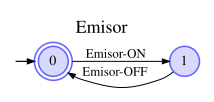

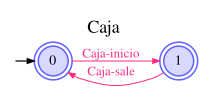

In [2]:
Emisor = fsa([0, 1], ['Emisor-ON', 'Emisor-OFF'],
             [(0, 'Emisor-ON', 1), (1, 'Emisor-OFF', 0)],
             [0], [0], Sigcon=['Emisor-ON', 'Emisor-OFF'], name='Emisor')
Caja = fsa([0, 1], ['Caja-inicio', 'Caja-sale'],
           [(0, 'Caja-inicio', 1), (1, 'Caja-sale', 0)],
           [0], [0, 1], Sigcon=set(), name='Caja')

G = Emisor // Caja
print('estados de la planta:', len(G.X))
draw(Emisor, Caja)

## 3. Especificaciones

| Especificación | Qué pide |
|---|---|
| `ESP_nueva_caja` | el emisor se enciende al inicio y, después, solo cuando la caja anterior salió de `SensorFin` (`Caja-sale`) |
| `ESP_emisor_off` | después de encenderse, el emisor se apaga cuando la caja corta el haz de `SensorInicio` (`Caja-inicio`) |

**Autolazos.** Como la planta puede generar `Caja-inicio` y `Caja-sale` aunque el emisor esté
apagado, cada especificación lleva un autolazo de esos eventos en los estados donde no los
restringe. Sin autolazos, la especificación prohibiría un evento no controlable que la planta
puede generar; la síntesis tendría que evitar ese estado y, como no puede impedir el evento,
quitaría estados hasta el inicial, y el supervisor quedaría vacío.

| Especificación | Estado | Autolazos |
|---|---|---|
| `ESP_nueva_caja` | 0: puede encender el emisor | `Caja-sale` |
| `ESP_emisor_off` | 0: emisor apagado | `Caja-inicio` |
| | 2: hay que apagar el emisor | `Caja-inicio` |

Cada especificación solo lleva autolazos de los eventos de su alfabeto: `Caja-inicio` queda libre
en `ESP_nueva_caja` y `Caja-sale` en `ESP_emisor_off`.

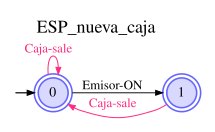

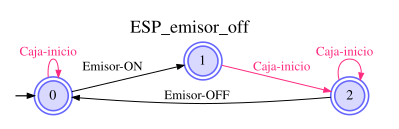

In [3]:
ESP_nueva_caja = fsa([0, 1], ['Emisor-ON', 'Caja-sale'],
                     [(0, 'Emisor-ON', 1), (1, 'Caja-sale', 0),
                      # autolazo
                      (0, 'Caja-sale', 0)],
                     [0], [0, 1], Sigcon=['Emisor-ON'], name='ESP_nueva_caja')
ESP_emisor_off = fsa([0, 1, 2], ['Emisor-ON', 'Emisor-OFF', 'Caja-inicio'],
                     [(0, 'Emisor-ON', 1), (1, 'Caja-inicio', 2), (2, 'Emisor-OFF', 0),
                      # autolazos
                      (0, 'Caja-inicio', 0), (2, 'Caja-inicio', 2)],
                     [0], [0, 1, 2], Sigcon=['Emisor-ON', 'Emisor-OFF'], name='ESP_emisor_off')
draw(ESP_nueva_caja, ESP_emisor_off)

## 4. Síntesis del supervisor

El supervisor es `supcontrollable(H, G)` con $H = G \parallel$ `ESP_nueva_caja` $\parallel$
`ESP_emisor_off`. Se comprueba que es controlable y no bloqueante.

estados de H: 9  estados del supervisor: 9
controlable: True
no bloqueante: True


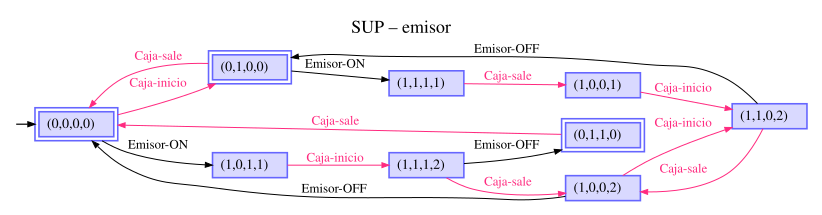

In [4]:
H = G // ESP_nueva_caja // ESP_emisor_off 
SUP = supcontrollable(H, G).setpar(name='$SUP$ -- emisor', style='rectangle')
print('estados de H:', len(H.X), ' estados del supervisor:', len(SUP.X))
print('controlable:', iscontrollable(SUP, G))
print('no bloqueante:', coac(SUP).X == SUP.X)
SUP

}

## 5. Mapa de señales

Las direcciones son las de un dispositivo esclavo Modbus en OpenPLC: las entradas discretas de
Factory I/O (Inputs) llegan a `%IX100.x` y las bobinas (Coils) salen por `%QX100.x`.

| Señal de Factory I/O | Modbus | OpenPLC | Variable |
|---|---|---|---|
| `SensorInicio` | Input 0 | `%IX100.0` | `SensorInicio` |
| `SensorFin` | Input 1 | `%IX100.1` | `SensorFin` |
| `Banda` | Coil 0 | `%QX100.0` | `Banda` |
| `Emisor` | Coil 1 | `%QX100.1` | `Emisor` |
| `Remover 0 (Remove)` | Coil 2 | `%QX100.2` | `Remover` |

`FE_INICIO` es el flanco de bajada de `SensorInicio` (un bloque `F_TRIG` en el programa) y
`RE_SALE` el flanco de subida de `SensorFin` (un bloque `R_TRIG`). La banda y el removedor no son
eventos del supervisor: `Mask` los deja encendidos en cada scan.

In [5]:
actuators = {
    'Emisor-ON': 'Emisor:ON:%QX100.1', 'Emisor-OFF': 'Emisor:OFF',
    'Caja-inicio': 'RE_INICIO:SensorInicio:%IX100.0',  # flanco de bajada: la caja corta el haz
    'Caja-sale': 'RE_SALE:SensorFin:%IX100.1',         # flanco de subida: la caja termina de pasar
}
Mask = {'TRUE': [('Banda', '%QX100.0'), ('Remover', '%QX100.2')]}

## 6. Generar el programa

Un solo supervisor con su planta, sin autómatas auxiliares ni pulsador de arranque
(`initial='null'`, el valor por defecto): el programa empieza en cuanto OpenPLC lo ejecuta.

In [6]:
from pathlib import Path

carpeta = Path('ST_generated')
nombre = 'Banda_simple_emisor'
st = generate_ST_OPENPLC([SUP], plants=[G], actuators=actuators, namest=nombre,
                         Mask=Mask, output_dir=carpeta)
archivo = carpeta / f'{nombre}.st'
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

programa guardado en ST_generated/Banda_simple_emisor.st
líneas: 125


In [7]:
print(st)
# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

(* OpenPLC random number (C code), used to pick one of several orders *)
FUNCTION_BLOCK random_number
	VAR_INPUT
		IN : BOOL;
	END_VAR
	VAR
		M : BOOL;
		INIT : BOOL;
	END_VAR
	VAR_OUTPUT
		OUT : DINT;
	END_VAR

	IF INIT = 0 THEN
		{#include <stdio.h>}
		{#include <stdlib.h>}
		IN := 1;
	END_IF;
	IF M = 0 and IN = 1 THEN
		{SetFbVar(OUT,rand())}
	END_IF;
END_FUNCTION_BLOCK
(* Controller generated by DESlab (generate_ST_OPENPLC). Every scan it: *)
(* 1. computes the input edges and a random number *)
(* 2. during the first second after the PLC starts, does nothing else *)
(* 3. each automaton moves with at most one uncontrollable event *)
(* 4. each automaton writes the orders enabled in its state; if there are several, it picks one at random *)
(* 5. each automaton moves with the order that was given (controllable event) *)
(* 6. copies signals to other outputs (Mask) *)
(* The states of each automaton are numbered from 0, its initial state: *)
(* state[0]: supervisor SUP -- emisor *)


/home/leonardo/datos/share_desktop/2026-II/Temas especiales de automatizacion/deslab/deslab-py3/notebooks/factory_io/ST_generated/Banda_simple_emisor.st

## 7. Llevarlo a Factory I/O y OpenPLC Runtime

**Factory I/O.** En *Drivers* elija *Modbus TCP/IP Server* y asigne `SensorInicio` a Input 0,
`SensorFin` a Input 1, `Banda` a Coil 0, `Emisor` a Coil 1 y `Remover 0 (Remove)` a Coil 2. Quite
los valores forzados (`FORCED`) de `Banda` y `Emisor`; si siguen forzados, la escena no obedece al
PLC. Anote la dirección IP y el puerto del servidor (en la escena, `192.168.0.9:502`, Slave ID 1).

**OpenPLC Runtime.**

1. En *Slave Devices* agregue un *Generic Modbus TCP Device* con la IP y el puerto de Factory I/O y
   Slave ID 1. Configure *Discrete Inputs* con inicio 0 y tamaño 2 (`%IX100.0` y `%IX100.1`) y
   *Coils* con inicio 0 y tamaño 3 (`%QX100.0` a `%QX100.2`).
2. En *Programs* cargue `ST_generated/Banda_simple_emisor.st` y compílelo.
3. Ponga la escena en marcha (*Run*) en Factory I/O y luego pulse *Start PLC* en OpenPLC.

**Qué se debe ver.** La banda arranca y no se detiene. El emisor se enciende, saca una caja y se
apaga cuando la caja corta el haz de `SensorInicio`. Cuando la caja termina de pasar `SensorFin` y
baja por la rampa, el emisor se enciende otra vez y saca la caja siguiente.

Si el programa reacciona en el momento contrario (cuando la caja se va de `SensorInicio` o cuando
llega a `SensorFin`), los sensores tienen la polaridad contraria: cambie `FE_` por `RE_` y viceversa
en el mapa de señales.